# Ejemplo R - Wine

In [2]:
library(rpart) #recursive and partitioning trees
library(plotly) #data visualization
library(rpart.plot)
library(RColorBrewer)
library(RWeka)
library(rattle)
library(ggplot2)
library(dplyr)
library(tidyr)

In [3]:
data(wine)

In [4]:
#table preview
knitr::kable(head(wine))



|Type | Alcohol| Malic|  Ash| Alcalinity| Magnesium| Phenols| Flavanoids| Nonflavanoids| Proanthocyanins| Color|  Hue| Dilution| Proline|
|:----|-------:|-----:|----:|----------:|---------:|-------:|----------:|-------------:|---------------:|-----:|----:|--------:|-------:|
|1    |   14.23|  1.71| 2.43|       15.6|       127|    2.80|       3.06|          0.28|            2.29|  5.64| 1.04|     3.92|    1065|
|1    |   13.20|  1.78| 2.14|       11.2|       100|    2.65|       2.76|          0.26|            1.28|  4.38| 1.05|     3.40|    1050|
|1    |   13.16|  2.36| 2.67|       18.6|       101|    2.80|       3.24|          0.30|            2.81|  5.68| 1.03|     3.17|    1185|
|1    |   14.37|  1.95| 2.50|       16.8|       113|    3.85|       3.49|          0.24|            2.18|  7.80| 0.86|     3.45|    1480|
|1    |   13.24|  2.59| 2.87|       21.0|       118|    2.80|       2.69|          0.39|            1.82|  4.32| 1.04|     2.93|     735|
|1    |   14.20|  1.76| 2.45|   

In [5]:
#Veamos la estructura delos datos
str(wine)

'data.frame':	178 obs. of  14 variables:
 $ Type           : Factor w/ 3 levels "1","2","3": 1 1 1 1 1 1 1 1 1 1 ...
 $ Alcohol        : num  14.2 13.2 13.2 14.4 13.2 ...
 $ Malic          : num  1.71 1.78 2.36 1.95 2.59 1.76 1.87 2.15 1.64 1.35 ...
 $ Ash            : num  2.43 2.14 2.67 2.5 2.87 2.45 2.45 2.61 2.17 2.27 ...
 $ Alcalinity     : num  15.6 11.2 18.6 16.8 21 15.2 14.6 17.6 14 16 ...
 $ Magnesium      : int  127 100 101 113 118 112 96 121 97 98 ...
 $ Phenols        : num  2.8 2.65 2.8 3.85 2.8 3.27 2.5 2.6 2.8 2.98 ...
 $ Flavanoids     : num  3.06 2.76 3.24 3.49 2.69 3.39 2.52 2.51 2.98 3.15 ...
 $ Nonflavanoids  : num  0.28 0.26 0.3 0.24 0.39 0.34 0.3 0.31 0.29 0.22 ...
 $ Proanthocyanins: num  2.29 1.28 2.81 2.18 1.82 1.97 1.98 1.25 1.98 1.85 ...
 $ Color          : num  5.64 4.38 5.68 7.8 4.32 6.75 5.25 5.05 5.2 7.22 ...
 $ Hue            : num  1.04 1.05 1.03 0.86 1.04 1.05 1.02 1.06 1.08 1.01 ...
 $ Dilution       : num  3.92 3.4 3.17 3.45 2.93 2.85 3.58 3.58 2.85 

In [6]:
summary(wine)

 Type      Alcohol          Malic            Ash          Alcalinity   
 1:59   Min.   :11.03   Min.   :0.740   Min.   :1.360   Min.   :10.60  
 2:71   1st Qu.:12.36   1st Qu.:1.603   1st Qu.:2.210   1st Qu.:17.20  
 3:48   Median :13.05   Median :1.865   Median :2.360   Median :19.50  
        Mean   :13.00   Mean   :2.336   Mean   :2.367   Mean   :19.49  
        3rd Qu.:13.68   3rd Qu.:3.083   3rd Qu.:2.558   3rd Qu.:21.50  
        Max.   :14.83   Max.   :5.800   Max.   :3.230   Max.   :30.00  
   Magnesium         Phenols        Flavanoids    Nonflavanoids   
 Min.   : 70.00   Min.   :0.980   Min.   :0.340   Min.   :0.1300  
 1st Qu.: 88.00   1st Qu.:1.742   1st Qu.:1.205   1st Qu.:0.2700  
 Median : 98.00   Median :2.355   Median :2.135   Median :0.3400  
 Mean   : 99.74   Mean   :2.295   Mean   :2.029   Mean   :0.3619  
 3rd Qu.:107.00   3rd Qu.:2.800   3rd Qu.:2.875   3rd Qu.:0.4375  
 Max.   :162.00   Max.   :3.880   Max.   :5.080   Max.   :0.6600  
 Proanthocyanins     Color 

In [7]:
# Ver cantidad total de valores faltantes
sum(is.na(wine))

[1] 0

In [8]:
# Ver cantidad de valores faltantes por variable
colSums(is.na(wine))

Type         Alcohol           Malic             Ash      Alcalinity 
              0               0               0               0               0 
      Magnesium         Phenols      Flavanoids   Nonflavanoids Proanthocyanins 
              0               0               0               0               0 
          Color             Hue        Dilution         Proline 
              0               0               0               0

In [9]:
# O también:
sapply(wine, class)

Type         Alcohol           Malic             Ash      Alcalinity 
       "factor"       "numeric"       "numeric"       "numeric"       "numeric" 
      Magnesium         Phenols      Flavanoids   Nonflavanoids Proanthocyanins 
      "integer"       "numeric"       "numeric"       "numeric"       "numeric" 
          Color             Hue        Dilution         Proline 
      "numeric"       "numeric"       "numeric"       "integer"

In [10]:
# Supongamos que tu dataset se llama 'wayne'
# Excluimos la columna 'tipo_de_vino' (ajustá el nombre si es distinto)
wine_long <- wine %>%
  select(-Type) %>%
  pivot_longer(cols = everything(), names_to = "variable", values_to = "valor")

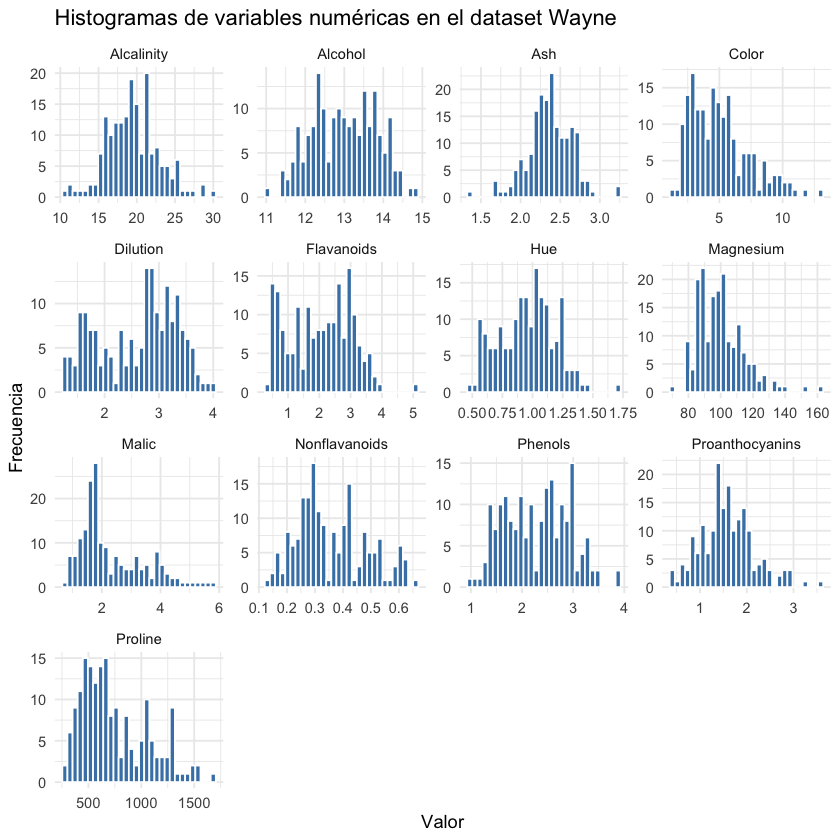

In [11]:
# Graficamos todos los histogramas en un solo objeto con facetado
ggplot(wine_long, aes(x = valor)) +
  geom_histogram(bins = 30, fill = "steelblue", color = "white") +
  facet_wrap(~ variable, scales = "free") +
  theme_minimal() +
  labs(title = "Histogramas de variables numéricas en el dataset Wayne",
       x = "Valor", y = "Frecuencia")

In [12]:
# Convertimos el dataset a formato largo, manteniendo la variable 'type'
wine_long <- wine %>%
  pivot_longer(cols = -Type, names_to = "variable", values_to = "valor")

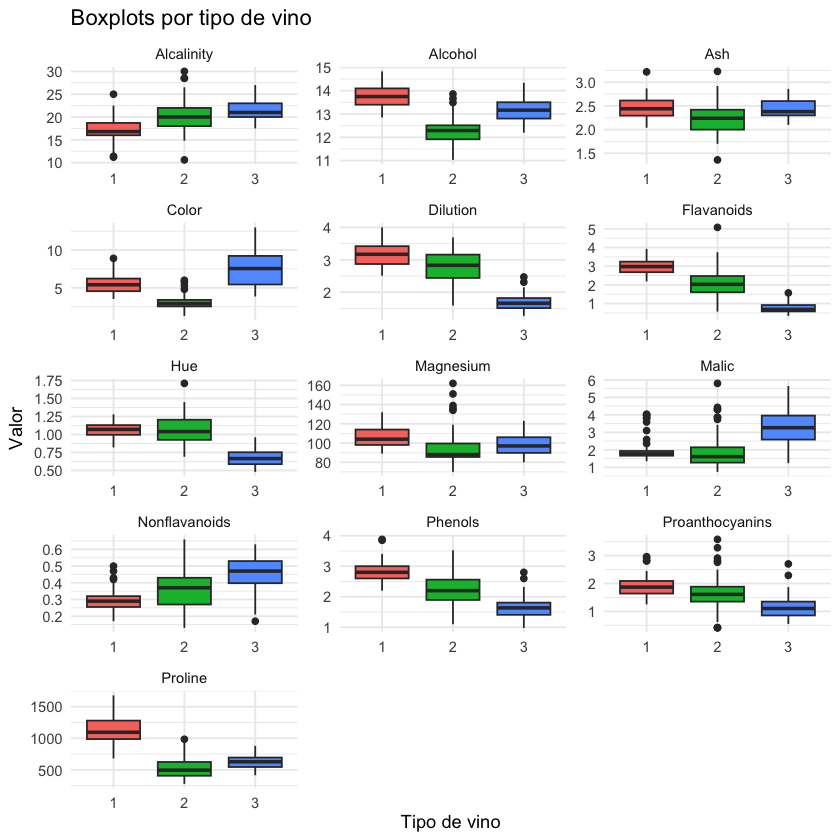

In [13]:
# Graficamos boxplots por tipo de vino para cada variable
ggplot(wine_long, aes(x = Type, y = valor, fill = Type)) +
  geom_boxplot() +
  facet_wrap(~ variable, scales = "free", ncol = 3) +
  theme_minimal() +
  labs(title = "Boxplots por tipo de vino",
       x = "Tipo de vino", y = "Valor") +
  theme(legend.position = "none")

In [14]:
# PASO 2": PREPARACIÓN DE DATOS
#Como se utiliza un árbol de decisión como modelo, 
#no es necesario preprocesar los datos

#training set
wine_train <- wine[1:3750, ]

#test set
wine_test <- wine[3751:4898, ]

n=178 (3572 observations deleted due to missingness)

node), split, n, loss, yval, (yprob)
      * denotes terminal node

 1) root 178 107 2 (0.33146067 0.39887640 0.26966292)  
   2) Proline>=755 67  10 1 (0.85074627 0.05970149 0.08955224)  
     4) Flavanoids>=2.165 59   2 1 (0.96610169 0.03389831 0.00000000) *
     5) Flavanoids< 2.165 8   2 3 (0.00000000 0.25000000 0.75000000) *
   3) Proline< 755 111  44 2 (0.01801802 0.60360360 0.37837838)  
     6) Dilution>=2.115 65   4 2 (0.03076923 0.93846154 0.03076923) *
     7) Dilution< 2.115 46   6 3 (0.00000000 0.13043478 0.86956522)  
      14) Hue>=0.9 7   2 2 (0.00000000 0.71428571 0.28571429) *
      15) Hue< 0.9 39   1 3 (0.00000000 0.02564103 0.97435897) *

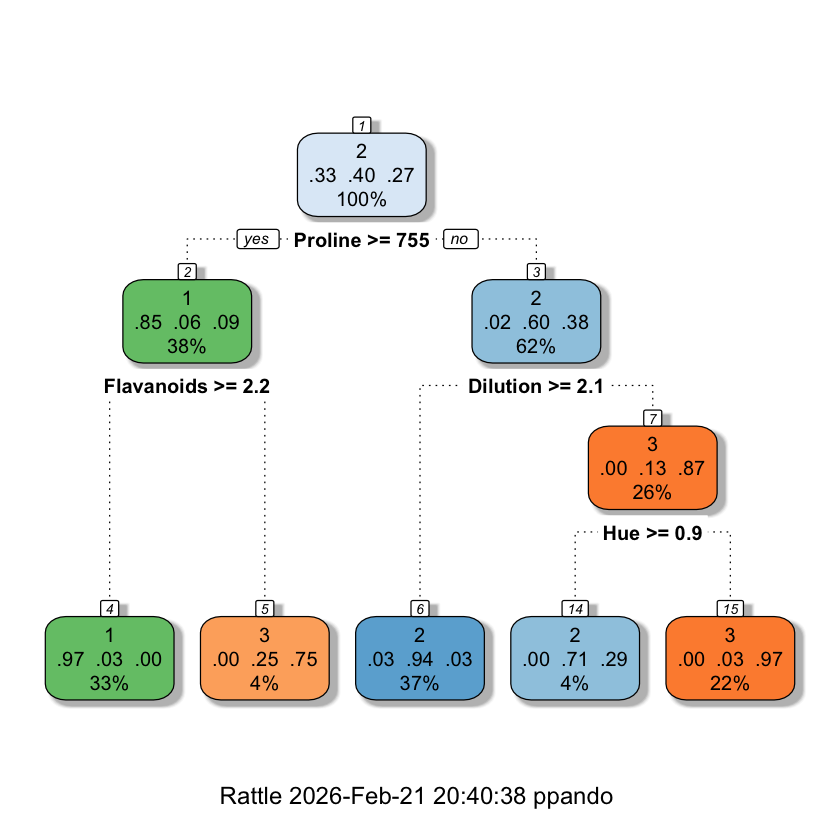

In [15]:
#PASO 3: ENTRENAMIENTO del modelo (Árbol de regresión)
#el paquete rpart (particionamiento recursivo) ofrece 
#la implementación más fiel a la descripción del algoritmo CART.

#building the model on training set
m.rpart <- rpart(Type ~. , data = wine_train)

m.rpart

fancyRpartPlot(m.rpart)

In [16]:
#PASO 4:EVALUACION DEL MODELO
#Ahora, es momento de poner a prueba el modelo de árbol de decisión 
#ejecutando los datos de prueba. 
p.rpart <- predict(m.rpart,wine_test)
p.rpart

,1,2,3
NA,0.03076923,0.9384615,0.03076923
NA.1,0.03076923,0.9384615,0.03076923
NA.2,0.03076923,0.9384615,0.03076923
NA.3,0.03076923,0.9384615,0.03076923
NA.4,0.03076923,0.9384615,0.03076923
NA.5,0.03076923,0.9384615,0.03076923
NA.6,0.03076923,0.9384615,0.03076923
NA.7,0.03076923,0.9384615,0.03076923
NA.8,0.03076923,0.9384615,0.03076923
NA.9,0.03076923,0.9384615,0.03076923
